# BFS, DFS and Dijkstra - Graph Algorithms Lab
**COSC 3100 Data Structures 2: 2T**

| | |
|---|---|
| Student name | Gulchehra Temirova |
| Student ID | 4250984 |
| Date | 31 October |

## How this notebook works
- **3 parts** (BFS, DFS, Dijkstra) with **one task each = 3 tasks**.
- Each part has: *explanation* → *worked example (given, run it)* → *1 task* (complete the `TODO`, the cell tests itself).
- Write your own code. A task is finished when its cell prints `passed`.
- Before submitting: **Kernel → Restart & Run All**, make sure nothing fails, save.

**Points (100):** 

Task 1 BFS 30  
Task 2 DFS 30 

Task 3 Dijkstra 40

**Colour code in drawings:** grey = unvisited, amber = waiting, red = current, green = visited/settled.

In [ ]:
import heapq, math
from collections import deque
import matplotlib.pyplot as plt

GRAY, AMBER, RED, GREEN = "#A8B3C4", "#F59E0B", "#E5484D", "#12A178"

def draw_graph(graph, pos, colors=None, weighted=False, title=""):
    colors = colors or {}
    fig, ax = plt.subplots(figsize=(5.5, 3.2))
    seen = set()
    for u in graph:
        for e in graph[u]:
            v, w = e if weighted else (e, None)
            if (v, u) in seen: continue
            seen.add((u, v))
            ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color=GRAY, zorder=1)
            if weighted:
                ax.text((pos[u][0] + pos[v][0]) / 2, (pos[u][1] + pos[v][1]) / 2, str(w), ha="center", va="center", fontsize=9,
                        bbox=dict(fc="white", ec=GRAY, boxstyle="round,pad=0.15"), zorder=2)
    for n, (x, y) in pos.items():
        c = colors.get(n, GRAY)
        ax.scatter([x], [y], s=700, color=c, zorder=3, edgecolors="white")
        ax.text(x, y, n, ha="center", va="center", fontweight="bold", color="white" if c in (RED, GREEN) else "#1F2937", zorder=4)
    ax.set_title(title); ax.axis("off"); plt.show()

graph = {"A": ["B", "C"], "B": ["A", "D", "E"], "C": ["A", "F"], "D": ["B"], "E": ["B", "F"], "F": ["C", "E", "G"], "G": ["F"]}
pos = {"A": (2, 3), "B": (1, 2), "C": (3, 2), "D": (0, 1), "E": (1.7, 1), "F": (3, 1), "G": (4, 1)}
draw_graph(graph, pos, title="Graph 1 (BFS and DFS)")

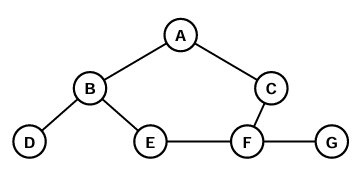

# Part 1: BFS (Breadth-First Search)
Explanation:

BFS explores a graph level by level: the start node, then all its neighbours, then their neighbours, and so on - like ripples in water.

It uses a queue (first in, first out): append at the back, popleft from the front.

Procedure

1. Put the start node in the queue and mark it discovered.
2. While the queue is not empty: remove the front node u, visit it, and for each undiscovered neighbour v mark it and add it to the back of the queue.

Key rule: mark a node when you enqueue it, so it can never enter the queue twice.

BFS counts edges, so it finds the path with the fewest edges in an unweighted graph. Time O(V + E), space O(V).

## Worked example (given)


In [ ]:
def bfs_trace(graph, start):
    discovered = {start}
    queue = deque([start])
    order = []
    print(f"init       queue = {list(queue)}")
    while queue:
        u = queue.popleft()                # dequeue from the FRONT
        order.append(u)                    # visit u
        new = []
        for v in graph[u]:
            if v not in discovered:
                discovered.add(v)          # mark when ENQUEUED
                queue.append(v)            # enqueue at the BACK
                new.append(v)
        print(f"dequeue {u}  enqueue {new!s:<10} queue = {list(queue)}")
    return order

order = bfs_trace(graph, "A")
print("visit order:", order)
draw_graph(graph, pos, colors={n: GREEN for n in order}, title="After BFS from A")

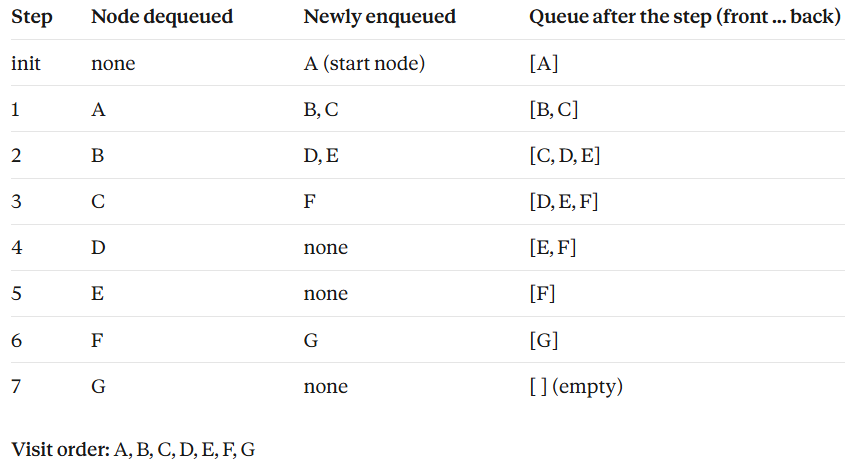

## Task 1 - Shortest path (fewest edges)

Write shortest_path(graph, source, target) that returns the path as a list of nodes, or None if there is no path.

In [ ]:
def shortest_path(graph, source, target):
    parent = {source: None}
    queue = deque([source])

    while queue:
        u = queue.popleft()
        if u == target:
            break
        for v in graph[u]:
            if v not in parent:
                parent[v] = u
                queue.append(v)

    if target not in parent:
        return None

    path = []
    node = target
    while node is not None:
        path.append(node)
        node = parent[node]
    return path[::-1]
    raise NotImplementedError

assert shortest_path(graph, "A", "G") == ["A", "C", "F", "G"]
assert shortest_path(graph, "D", "D") == ["D"]
assert len(shortest_path(graph, "D", "G")) == 5
assert shortest_path({"X": ["Y"], "Y": ["X"], "Z": []}, "X", "Z") is None
print("Task 1 passed")

Task 1 passed

# Part 2 - DFS (Depth-First Search )
Idea:
DFS goes as deep as possible along one branch, then backtracks. Use an explicit stack (last in, first out). 

A node is marked when it is popped, so the same node can be in the stack twice and the second copy is skipped. 

Pushing neighbours in reverse order makes the alphabetically first neighbour come out first.

Key rule: here a node is marked when it is popped, so it may sit in the stack twice; the second copy is skipped.

Time O(V + E), space O(V). Used for cycle detection, topological sort, components, maze solving.

In [ ]:
def dfs_trace(graph, start):
    stack = [start]
    visited = []
    print(f"init     stack(top first) = {stack[::-1]}")
    while stack:
        u = stack.pop()                              # pop from the TOP
        if u in visited:
            print(f"pop {u} (already visited, skip)  stack = {stack[::-1]}")
            continue
        visited.append(u)
        new = [v for v in graph[u] if v not in visited]
        for v in reversed(new):                      # reversed: first neighbour ends on top
            stack.append(v)
        print(f"pop {u}  push {new!s:<12} stack = {stack[::-1]}")
    return visited

order = dfs_trace(graph, "A")
print("visit order:", order)
draw_graph(graph, pos, colors={n: GREEN for n in order}, title="After DFS from A")

def dfs_recursive(graph, u, visited=None):      # GIVEN: recursive version (the call stack is the stack)
    if visited is None:
        visited = []
    visited.append(u)
    for v in graph[u]:
        if v not in visited:
            dfs_recursive(graph, v, visited)
    return visited

print("recursive order:", dfs_recursive(graph, "A"))

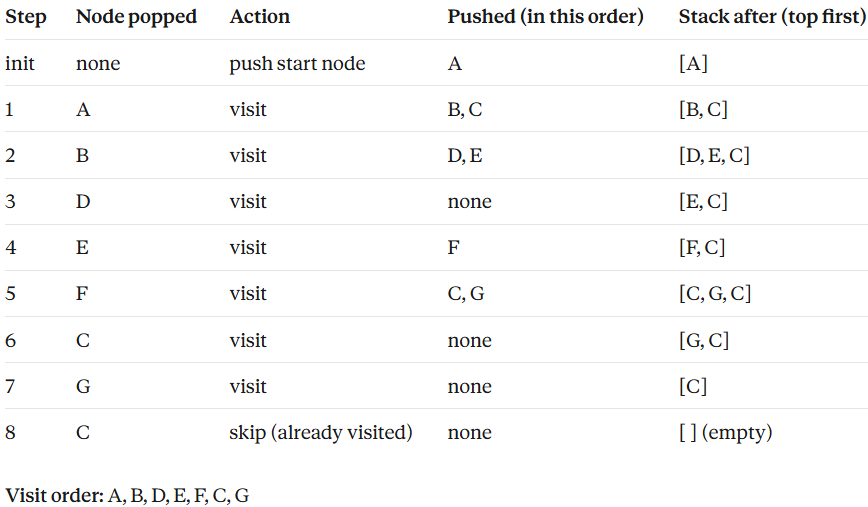

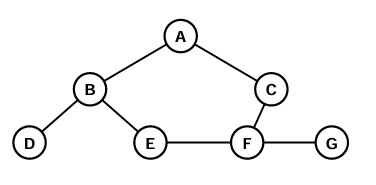

# Task 2 - Iterative DFS

Write dfs_iterative(graph, start) that returns
the visit order. Use a list as the stack and the mark on pop rule.

In [ ]:
def dfs_iterative(graph, start):
    stack = [start]
    visited = []

    while stack:
        u = stack.pop()
        if u in visited:
            continue
        visited.append(u)

        for v in reversed(graph[u]):
            if v not in visited:
                stack.append(v)

    return visited
    raise NotImplementedError

assert dfs_iterative(graph, "A") == ["A", "B", "D", "E", "F", "C", "G"]
assert dfs_iterative(graph, "G") == ["G", "F", "C", "A", "B", "D", "E"]
assert dfs_iterative(graph, "A") == dfs_recursive(graph, "A")
print("Task 2 passed")

Task 2 passed

# Part 3 - Dijkstra's Shortest-Path Algorithm
Idea. Dijkstra finds the cheapest path from one source to every node when all weights are non-negative.

Keep dist (best known cost, INF at the start, 0 for the source) and prev (node before it on that path).

Repeatedly settle the unsettled node with the smallest dist, then relax its edges.

Procedure

1. dist[source] = 0, all others ∞; push (0, source) on the heap.
2. Pop the smallest (d, u). If u is already settled, skip it. Settle u - its distance is final.
3. Relax each edge (u, v, w): if dist[u] + w < dist[v], set dist[v] = dist[u] + w, prev[v] = u and push (dist[v], v).
4. Repeat until the heap is empty.

In [ ]:
wgraph = {
    "A": [("B", 4), ("C", 2)],
    "B": [("A", 4), ("C", 1), ("D", 5)],
    "C": [("A", 2), ("B", 1), ("D", 8), ("E", 10)],
    "D": [("B", 5), ("C", 8), ("E", 2), ("F", 6)],
    "E": [("C", 10), ("D", 2), ("F", 3)],
    "F": [("D", 6), ("E", 3)],
}
wpos = {"A": (0, 1), "B": (1, 2), "C": (1, 0), "D": (2.3, 1.7), "E": (2.4, 0.1), "F": (3.5, 1)}

def dijkstra_trace(graph, src):
    dist = {n: math.inf for n in graph}
    prev = {n: None for n in graph}
    dist[src] = 0
    pq, done = [(0, src)], []

    def show(title):
        print(f"\n{title}")
        print("node  dist  prev  status")
        for n in graph:
            d = "inf" if dist[n] == math.inf else dist[n]
            st = "settled" if n in done else ("candidate" if dist[n] < math.inf else "-")
            print(f"  {n}   {d!s:>4}   {prev[n] or '-'!s:>3}   {st}")

    show("init")
    while pq:
        d, u = heapq.heappop(pq)
        if u in done:
            continue
        done.append(u)
        for v, w in graph[u]:
            if v not in done and d + w < dist[v]:     # relaxation
                dist[v], prev[v] = d + w, u
                heapq.heappush(pq, (dist[v], v))
        show(f"settle {u} (dist {d})")
    return dist, prev

def path_to(prev, target):                       # GIVEN: rebuild a path from the prev table
    path = []
    while target is not None:
        path.append(target)
        target = prev[target]
    return path[::-1]

dist, prev = dijkstra_trace(wgraph, "A")
print("\npath to F:", " -> ".join(path_to(prev, "F")), "cost", dist["F"])
draw_graph(wgraph, wpos, weighted=True, colors={n: GREEN for n in wgraph}, title="All nodes settled")

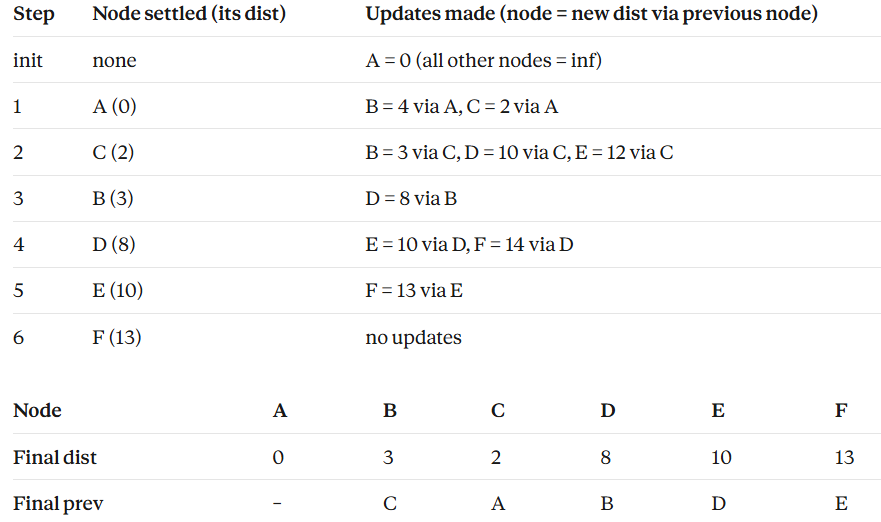

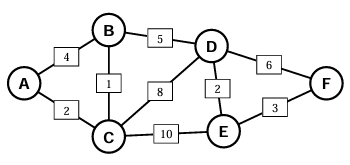

# Task 3 - Implement Dijkstra
Write dijkstra(graph, src) returning two dictionaries (dist, prev). Use heapq. Skip nodes that are already settled. Unreachable nodes keep math.inf.

In [ ]:
def dijkstra(graph, src):
    dist = {n: math.inf for n in graph}
    prev = {n: None for n in graph}
    dist[src] = 0

    pq = [(0, src)]
    done = set()

    while pq:
        d, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u)

        for v, w in graph[u]:
            if v not in done and d + w < dist[v]:
                dist[v] = d + w
                prev[v] = u
                heapq.heappush(pq, (dist[v], v))

    return dist, prev
    raise NotImplementedError

dist, prev = dijkstra(wgraph, "A")
assert dist == {"A": 0, "B": 3, "C": 2, "D": 8, "E": 10, "F": 13}
assert prev["F"] == "E" and prev["B"] == "C" and prev["A"] is None
assert path_to(prev, "F") == ["A", "C", "B", "D", "E", "F"]
print("cost to F:", dist["F"], "via", " -> ".join(path_to(prev, "F")))
print("Task 3 passed")


cost to F:
 13 via A -> C -> B -> D -> E -> F
Task 3 passed